In [1]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [2]:
import os
# Parent dir
parent_dir = "/content/drive/MyDrive"


In [3]:
import pandas as pd
import numpy as np


In [4]:
btc_train = pd.read_csv(parent_dir+"/btc_train.csv")
btc_test  = pd.read_csv(parent_dir+"/btc_test.csv")

tweet_train = pd.read_csv(parent_dir+"/tweet_train.csv")
tweet_test  = pd.read_csv(parent_dir+"/tweet_test.csv")

In [5]:
def parkinson_vol(df):
    return np.sqrt((1 / (4 * np.log(2))) * (np.log(df["High"] / df["Low"]) ** 2))


In [6]:
# --- Train ---
btc_train = btc_train.copy()
btc_train["rv"] = parkinson_vol(btc_train)

vol_threshold = btc_train["rv"].quantile(0.75)  # top 25% = high-vol regime

btc_train["high_vol_next"] = (
    btc_train["rv"].shift(-1) > vol_threshold
).astype(int)

btc_train = btc_train.dropna()

# --- Test ---
btc_test = btc_test.copy()
btc_test["rv"] = parkinson_vol(btc_test)

btc_test["high_vol_next"] = (
    btc_test["rv"].shift(-1) > vol_threshold
).astype(int)

btc_test = btc_test.dropna()


In [7]:
def make_market_features(df):
    out = df.copy()

    out["ret_1"] = np.log(out["Close"]).diff()
    out["ret_5"] = np.log(out["Close"]).diff(5)

    out["vol_5"] = out["ret_1"].rolling(5).std()
    out["vol_10"] = out["ret_1"].rolling(10).std()

    out["range"] = (out["High"] - out["Low"]) / out["Close"]
    out["volume_z"] = (out["Volume"] - out["Volume"].rolling(20).mean()) / \
                       out["Volume"].rolling(20).std()

    return out.dropna()


In [8]:
btc_train_feat = make_market_features(btc_train)
btc_test_feat  = make_market_features(btc_test)


In [9]:
def aggregate_tweets(df):
    return (
        df.groupby("day")
          .agg(
              sentiment_mean=("sentiment_score", "mean"),
              sentiment_std=("sentiment_score", "std"),
              tweet_count=("sentiment_score", "count"),
              likes_sum=("like_count", "sum"),
              retweets_sum=("retweet_count", "sum"),
          )
          .fillna(0)
          .reset_index()
    )


In [10]:
tweet_train_daily = aggregate_tweets(tweet_train)
tweet_test_daily  = aggregate_tweets(tweet_test)


In [11]:
train_df = btc_train_feat.merge(tweet_train_daily, on="day", how="left").fillna(0)
test_df  = btc_test_feat.merge(tweet_test_daily,  on="day", how="left").fillna(0)


In [12]:
target = "high_vol_next"

feature_cols = [
    # market
    "ret_1", "ret_5", "vol_5", "vol_10",
    "range", "volume_z",
    # sentiment
    "sentiment_mean", "sentiment_std",
    "tweet_count", "likes_sum", "retweets_sum"
]

X_train = train_df[feature_cols]
y_train = train_df[target]

X_test = test_df[feature_cols]
y_test = test_df[target]


In [14]:
!pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 8.8 MB/s eta 0:00:00


In [15]:
from catboost import CatBoostClassifier
from sklearn.metrics import classification_report, roc_auc_score


In [16]:
model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    eval_metric="AUC",
    random_seed=42,
    verbose=False
)

model.fit(X_train, y_train)


In [17]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print("ROC-AUC:", roc_auc_score(y_test, y_prob))


              precision    recall  f1-score   support

           0       0.84      0.98      0.91       129
           1       0.33      0.04      0.07        25

    accuracy                           0.83       154
   macro avg       0.59      0.51      0.49       154
weighted avg       0.76      0.83      0.77       154

ROC-AUC: 0.5813953488372093


In [18]:
import pandas as pd

feat_imp = pd.Series(
    model.get_feature_importance(),
    index=feature_cols
).sort_values(ascending=False)

print(feat_imp)


sentiment_mean    12.051089
volume_z          11.462670
ret_5             10.650764
likes_sum         10.399700
ret_1              8.766505
vol_10             8.601296
tweet_count        8.366647
sentiment_std      8.020867
range              7.887537
retweets_sum       7.018753
vol_5              6.774173
dtype: float64


In [19]:
from sklearn.metrics import precision_recall_curve

precision, recall, thresholds = precision_recall_curve(y_test, y_prob)

# Example: maximize F1
f1 = 2 * (precision * recall) / (precision + recall + 1e-8)
best_idx = f1.argmax()
best_threshold = thresholds[best_idx]

best_threshold


np.float64(0.004674568605557911)

In [20]:
y_pred_adj = (y_prob > best_threshold).astype(int)
print(classification_report(y_test, y_pred_adj))


              precision    recall  f1-score   support

           0       0.93      0.19      0.32       129
           1       0.18      0.92      0.30        25

    accuracy                           0.31       154
   macro avg       0.55      0.56      0.31       154
weighted avg       0.81      0.31      0.32       154



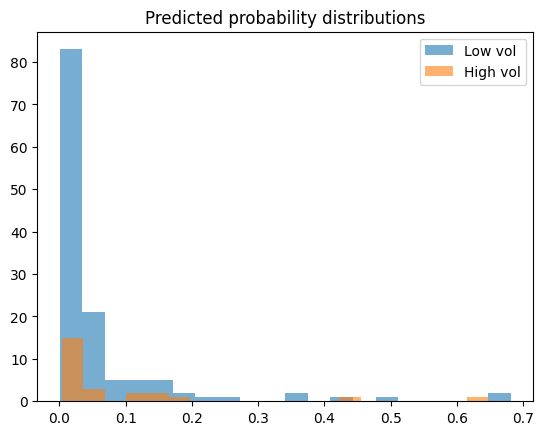

In [21]:
import matplotlib.pyplot as plt

plt.hist(y_prob[y_test == 0], bins=20, alpha=0.6, label="Low vol")
plt.hist(y_prob[y_test == 1], bins=20, alpha=0.6, label="High vol")
plt.legend()
plt.title("Predicted probability distributions")
plt.show()


In [22]:
btc_train["rv_smooth"] = btc_train["rv"].rolling(3).mean()
btc_test["rv_smooth"] = btc_test["rv"].rolling(3).mean()

vol_threshold = btc_train["rv_smooth"].quantile(0.75)

btc_train["high_vol_next"] = (
    btc_train["rv_smooth"].shift(-1) > vol_threshold
).astype(int)

btc_test["high_vol_next"] = (
    btc_test["rv_smooth"].shift(-1) > vol_threshold
).astype(int)


In [23]:
btc_train_feat["rv_lag1"] = btc_train_feat["rv"].shift(1)
btc_train_feat["rv_lag2"] = btc_train_feat["rv"].shift(2)

btc_test_feat["rv_lag1"] = btc_test_feat["rv"].shift(1)
btc_test_feat["rv_lag2"] = btc_test_feat["rv"].shift(2)

btc_train_feat = btc_train_feat.dropna()
btc_test_feat = btc_test_feat.dropna()


In [24]:
model = CatBoostClassifier(
    iterations=800,
    depth=6,
    learning_rate=0.03,
    loss_function="Logloss",
    eval_metric="F1",
    class_weights=[1.0, 4.0],  # emphasize high-vol
    random_seed=42,
    verbose=False
)


In [25]:
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import f1_score

tscv = TimeSeriesSplit(n_splits=4)

best_thresh = []
for train_idx, val_idx in tscv.split(X_train):
    model.fit(X_train.iloc[train_idx], y_train.iloc[train_idx])
    probs = model.predict_proba(X_train.iloc[val_idx])[:,1]

    thresholds = np.linspace(0.1, 0.9, 50)
    f1s = [f1_score(y_train.iloc[val_idx], probs > t) for t in thresholds]
    best_thresh.append(thresholds[np.argmax(f1s)])

final_threshold = np.mean(best_thresh)


In [26]:
y_pred_adj = (y_prob > final_threshold).astype(int)
print(classification_report(y_test, y_pred_adj))


              precision    recall  f1-score   support

           0       0.84      0.95      0.89       129
           1       0.25      0.08      0.12        25

    accuracy                           0.81       154
   macro avg       0.55      0.52      0.51       154
weighted avg       0.75      0.81      0.77       154

